# 12 - Core Calibration and the Digital Core

**Part B - Petrophys Curriculum**

Wireline logs are *indirect* measurements. A neutron tool counts hydrogen, a
density tool counts back-scattered gamma rays - neither one *is* porosity. The
ground truth against which every log interpretation is ultimately judged is the
**core**: a physical cylinder of rock brought to surface and measured in the
laboratory.

This notebook has two halves:

1. **Core-to-log calibration** - tie laboratory helium porosity and Klinkenberg
   permeability to the logs, quantify the mismatch ($R^2$, bias, RMSE), and fit a
   **poro-perm transform** so we can predict permeability everywhere the core did
   not sample.
2. **The digital core** - the modern, high-resolution successor to plug-based
   analysis. We classify **facies** with weighted K-means (`DigitalCoreFacies`),
   turn **XRF** elemental scans into mineral proxies (`XRFData`), classify
   **grain size** on the Wentworth scale (`GrainSizeData`), and derive dynamic
   elastic moduli from **core mechanical** velocities (`CoreMechanical`).

We use the real cored well **30/6-5** (Oseberg, North Sea) for the calibration
work, and clearly-flagged *illustrative synthetic* datasets for the digital-core
tools where no scanner data ships with the library.

## Learning goals

By the end of this notebook you will be able to:

- Build a `CoreData` container directly from a cored well with
  `petrophys.core.core_data_from_well`.
- Calibrate a log-derived porosity against core with `calibrate_porosity`, and
  read the calibration statistics off a `CalibrationResult`.
- Fit a linear porosity correction (`fit_porosity_correction`) and a poro-perm
  transform (`fit_poro_perm_transform`), then apply the transform to the log.
- Cluster multi-parameter core data into facies with `DigitalCoreFacies` /
  `FaciesResult`, and produce a per-facies statistics table.
- Convert `XRFData` elemental logs into `mineral_proxies()` and
  `elemental_ratios()`.
- Classify `GrainSizeData` on the Wentworth scale and estimate Kozeny-Carman
  permeability.
- Compute dynamic Young's modulus, Poisson's ratio, and Vp/Vs from
  `CoreMechanical`.

## Why this matters

Every deterministic petrophysical answer - porosity, saturation, net pay,
volumes - inherits the systematic error of the logs it was built from. Core
calibration is how we *anchor* those logs to reality:

- **Porosity** measured by a density tool depends on an assumed matrix density.
  Get the grain density wrong and every porosity is biased. Core helium porosity
  fixes the tie point.
- **Permeability** is never measured by wireline; it is *always* a correlation.
  A poro-perm transform fitted to core plugs is the standard way to propagate a
  handful of lab measurements to the full log.

The **digital core** pushes this further. Instead of one plug every ~30 cm,
modern core scanners deliver *continuous* millimetre-to-centimetre logs of grain
size, elemental chemistry, strength, and colour. Clustering these into facies
gives a rock-typing scheme that is fully data-driven and reproducible - the
workflow used by service companies such as EpsLog / Stratum Reservoir.

> **Units convention.** In `petrophys`, porosity and saturation are stored as
> **fractions (v/v, 0-1)**, permeability in **mD**, grain/bulk density in
> **g/cm3**, grain size in **micrometres (um)**, and velocities in **m/s**.

### Prerequisites

Assumes the Part A porosity and permeability notebooks (04, 08). The digital-core
tools depend on **scikit-learn** for K-means clustering; this is installed in the
`xtts_env` kernel.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys', petrophys.__version__)
print('geolink wells:', petrophys.list_samples('geolink'))

petrophys 0.1.0
geolink wells: ['15_9-14', '16_7-1', '25_5-1', '30_6-5']


---
## Part 1 - Core-to-log calibration

### 1.1 Loading core measurements from the well

Well **30/6-5** is unusual and convenient: it ships with the laboratory core
measurements already merged into the LAS file as dedicated curves -
`PHIC` (core helium porosity), `KH_CORE` (horizontal Klinkenberg permeability),
`GDEN` (grain density), and `SWC` / `SOC` (Dean-Stark saturations).

`core_data_from_well` sweeps the well for these mnemonics and packs the samples
that actually carry a lab measurement into a `CoreData` object.

In [2]:
well = read_las(petrophys.sample('30_6-5'))

# Sanitize the field name for ASCII printing (this header has mojibake).
field_ascii = (well.header.field or 'Unknown').encode('ascii', 'replace').decode('ascii')
print('Well :', well.name, '| field:', field_ascii)
print('Depth: %.1f - %.1f %s' % (well.start_depth, well.stop_depth, well.depth_unit))
print('Curves present:', ', '.join(well.curves))

Well : 30/6-5 | field: OSEBERG ??ST
Depth: 176.6 - 3556.1 m
Curves present: LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RMED, BS, PHIC, GDEN, KH_CORE, KV_CORE, SWC, SOC


In [3]:
from petrophys.core import core_data_from_well

core = core_data_from_well(well)
print(core)
print()
print('Plugs                :', core.n_plugs)
print('Cored interval       : %.1f - %.1f %s' % (core.top, core.bottom, well.depth_unit))
print('Porosity source curve:', core.metadata.get('core_porosity_curve'))
print('Perm source curve    :', core.metadata.get('core_permeability_curve'))
print('GD source curve      :', core.metadata.get('core_grain_density_curve'))
print()
print('Valid porosity plugs :', int(np.isfinite(core.porosity).sum()))
print('Valid perm plugs     :', int(np.isfinite(core.permeability).sum()))
print('Core porosity range  : %.3f - %.3f v/v' % (np.nanmin(core.porosity), np.nanmax(core.porosity)))
print('Core perm range      : %.2f - %.1f mD' % (np.nanmin(core.permeability), np.nanmax(core.permeability)))

CoreData(plugs=201, depth=2800.5-2947.9, props=[porosity, perm, GD, Sw])

Plugs                : 201
Cored interval       : 2800.5 - 2947.9 m
Porosity source curve: PHIC
Perm source curve    : KH_CORE
GD source curve      : GDEN

Valid porosity plugs : 200
Valid perm plugs     : 198
Core porosity range  : 0.022 - 0.277 v/v
Core perm range      : 0.02 - 5826.0 mD


### 1.2 Calibrating an *independent* log porosity

To calibrate honestly we must compare core against a log porosity that was
computed **independently** of the core. (Comparing `PHIC` against itself would
trivially give $R^2 = 1$.) So we compute a fresh **density porosity** from the
bulk-density curve using the textbook relation

$$\phi_D = \frac{\rho_{ma} - \rho_b}{\rho_{ma} - \rho_f}$$

with an *assumed* sandstone matrix density $\rho_{ma} = 2.65$ g/cm3 and fluid
density $\rho_f = 1.0$ g/cm3. The whole point of calibration is to discover how
wrong those assumptions are.

In [4]:
RHO_MA = 2.65   # assumed quartz matrix density (g/cm3)
RHO_F  = 1.00   # assumed fluid density (g/cm3)

rhob = np.asarray(well.get('RHOB').data, dtype=float)
phid = np.clip((RHO_MA - rhob) / (RHO_MA - RHO_F), 0.0, 0.5)
well.add_curve('PHID', phid, 'v/v', 'Density porosity (rho_ma=2.65)')

print('PHID added. Mean density porosity: %.3f v/v' % np.nanmean(phid))

PHID added. Mean density porosity: 0.286 v/v


In [5]:
from petrophys.core import calibrate_porosity

cal = calibrate_porosity(well, core, log_curve='PHID')
print('Core vs log density-porosity calibration')
print('  n points  :', cal.n_points)
print('  R^2       : %.3f' % cal.r_squared)
print('  Bias (log-core): %+.4f v/v' % cal.bias)
print('  RMSE      : %.4f v/v' % cal.rmse)
print('  Linear fit: log = %.3f * core + %.4f' % (cal.slope, cal.intercept))

Core vs log density-porosity calibration
  n points  : 200
  R^2       : 0.645
  Bias (log-core): -0.0198 v/v
  RMSE      : 0.0461 v/v
  Linear fit: log = 0.860 * core + 0.0045


A **positive bias** means the log reads systematically *higher* than core; a
negative bias means it reads low. On 30/6-5 the density porosity runs slightly
**low** relative to core, and the scatter ($R^2 \approx 0.65$) reflects the
assumed matrix density not being exactly right for every plug - exactly the kind
of systematic error calibration exists to expose.

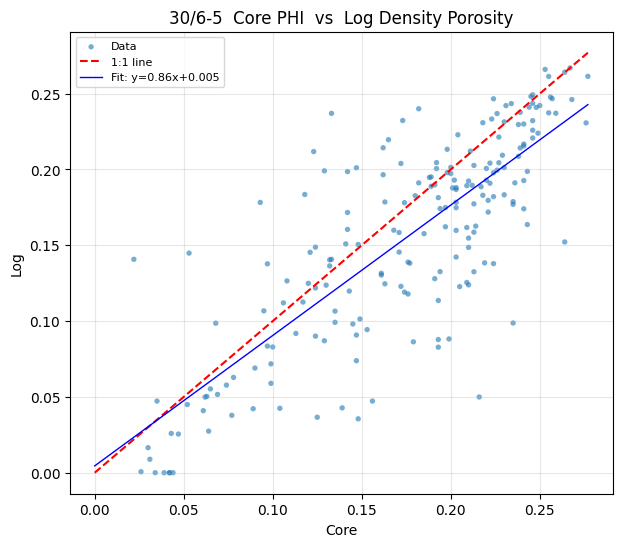

In [6]:
from petrophys.core import plot_calibration

fig, ax = plot_calibration(cal, title='30/6-5  Core PHI  vs  Log Density Porosity')
plt.show()

### 1.3 A porosity correction

`fit_porosity_correction` fits $\phi_{core} = A\,\phi_{log} + B$ so we can map
the *full* log porosity onto its core-equivalent value. This is the transfer
function you would apply downstream before computing volumes.

In [7]:
from petrophys.core import fit_porosity_correction

corr = fit_porosity_correction(well, core, log_curve='PHID')
print(corr)
print()
# Apply to two example log readings
for phi_log in (0.10, 0.25):
    print('  log phi %.2f -> core-equivalent %.3f' % (phi_log, float(corr.predict(phi_log))))

PorosityCorrection(PHIcore = 0.717*PHID + 0.065, R^2=0.580, RMSE=0.0383, n=193)

  log phi 0.10 -> core-equivalent 0.136
  log phi 0.25 -> core-equivalent 0.244


### 1.4 Fitting a poro-perm transform

Permeability spans orders of magnitude, so the industry-standard transform is
linear in **log10** space:

$$\log_{10}(k) = A\,\phi + B \quad\Longleftrightarrow\quad k = 10^{B}\,10^{A\phi}$$

`fit_poro_perm_transform` fits this straight from the `CoreData` porosity and
permeability arrays.

In [8]:
from petrophys.core import fit_poro_perm_transform

transform = fit_poro_perm_transform(core)
print('Poro-perm transform (log10 K = A*phi + B)')
print('  A (slope)    : %.2f' % transform.A)
print('  B (intercept): %.2f' % transform.B)
print('  R^2          : %.3f' % transform.r_squared)
print('  n plugs      :', transform.n_points)
print()
for phi in (0.10, 0.20, 0.30):
    print('  phi %.2f -> k = %.2f mD' % (phi, float(transform.predict(phi))))

Poro-perm transform (log10 K = A*phi + B)
  A (slope)    : 21.72
  B (intercept): -2.54
  R^2          : 0.777
  n plugs      : 198

  phi 0.10 -> k = 0.43 mD
  phi 0.20 -> k = 64.23 mD
  phi 0.30 -> k = 9540.29 mD


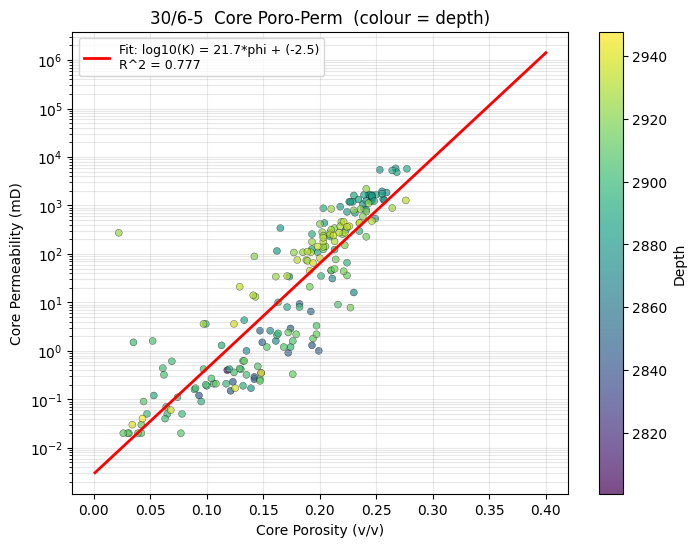

In [9]:
from petrophys.core import plot_poro_perm

fig, ax = plot_poro_perm(core, transform=transform,
                         title='30/6-5  Core Poro-Perm  (colour = depth)')
plt.show()

### 1.5 Applying the transform back onto the log

`apply_poro_perm_transform` writes a continuous predicted-permeability curve onto
the well using a chosen porosity input. We feed it our density porosity so the
prediction covers the *entire* logged interval, not just the cored plugs - the
whole reason for building the transform.

In [10]:
from petrophys.core import apply_poro_perm_transform

perm_pred = apply_poro_perm_transform(well, transform,
                                      porosity_curve='PHID',
                                      output_curve='PERM_TRANS')
print('Predicted permeability curve PERM_TRANS added to well.')
finite = perm_pred[np.isfinite(perm_pred)]
print('  samples     :', finite.size)
print('  median k    : %.2f mD' % np.median(finite))
print('  P10 / P90   : %.2f / %.1f mD' % (np.percentile(finite, 10), np.percentile(finite, 90)))

Predicted permeability curve PERM_TRANS added to well.
  samples     : 22171
  median k    : 41653.86 mD
  P10 / P90   : 0.03 / 100000.0 mD


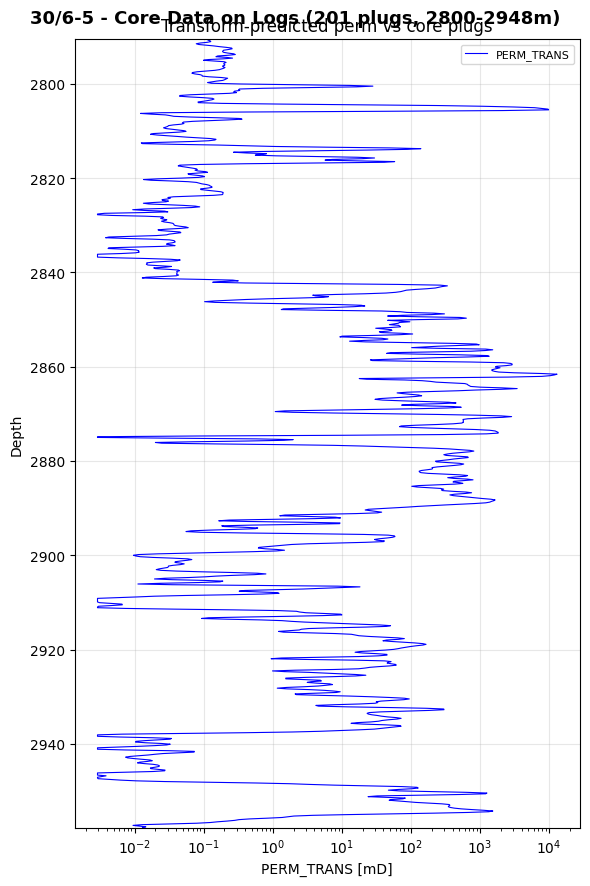

In [11]:
# Overlay: continuous predicted perm vs the discrete core plugs, over the cored interval.
# PERM_TRANS is already on the well; plot_core_on_logs maps any "PERM"-named curve to a
# semilogx track and overlays the core K plugs automatically (see core_map in core/plots.py).
from petrophys.core import plot_core_on_logs

fig, axes = plot_core_on_logs(
    well, core,
    curves=['PERM_TRANS'],
    depth_range=(core.top - 10, core.bottom + 10),
    figsize=(6, 9),
)
axes[0].set_title('Transform-predicted perm vs core plugs')
plt.show()

---
## Part 2 - The digital core

Plug-based core analysis samples one point every ~30 cm. Modern **core scanning**
delivers *continuous* high-resolution logs: laser grain size, XRF elemental
chemistry, scratch-test strength, ultrasonic velocities, and RGB colour. The
`petrophys.core` digital-core suite ingests these and turns them into
interpretation-ready products.

> **Data note.** The Oseberg 30/6-5 LAS does not ship with scanner data, so from
> here on we build **small, clearly-labelled synthetic datasets** whose values
> are physically plausible but *illustrative only*. They exist to demonstrate the
> API and the workflow, not to represent the real well.

### 2.1 Facies classification with weighted K-means

`DigitalCoreFacies` standardises each input feature, applies an optional
`sqrt(weight)` emphasis, and runs K-means. The result is a `FaciesResult`
carrying the per-sample labels, cluster centroids (back in original units), and
convenience methods `proportions()` and `statistics()`.

Here we use **real 30/6-5 wireline logs** (GR, RHOB, NPHI, PEF) over the cored
interval as the multi-parameter feature set - a legitimate electrofacies
exercise - to keep the demonstration grounded in real data.

In [12]:
from petrophys.core import DigitalCoreFacies

# Real logs over the cored interval as clustering features.
top, bottom = core.top, core.bottom
dep = np.asarray(well.depth, dtype=float)
m = (dep >= top) & (dep <= bottom)

features = {
    'GR':   np.asarray(well.get('GR').data,   dtype=float)[m],
    'RHOB': np.asarray(well.get('RHOB').data, dtype=float)[m],
    'NPHI': np.asarray(well.get('NPHI').data, dtype=float)[m],
    'PEF':  np.asarray(well.get('PEF').data,  dtype=float)[m],
}
depth_m = dep[m]
print('Samples in interval:', depth_m.size)
print('Finite per feature :', {k: int(np.isfinite(v).sum()) for k, v in features.items()})

Samples in interval: 968
Finite per feature : {'GR': 968, 'RHOB': 968, 'NPHI': 968, 'PEF': 968}


In [13]:
clf = DigitalCoreFacies(n_facies=4, n_init=10, random_state=42)
result = clf.fit(depth_m, features, weights={'GR': 2.0})   # emphasise GR (shaliness)

print('Facies model fitted.')
print('  n_facies :', result.n_facies)
print('  inertia  : %.1f' % result.inertia)
print('  labels   :', np.unique(result.facies[result.facies > 0]))
print()
print('Facies proportions:')
for fc, frac in result.proportions().items():
    print('  facies %d : %5.1f %%' % (fc, 100 * frac))

Facies model fitted.
  n_facies : 4
  inertia  : 1264.9
  labels   : [1 2 3 4]

Facies proportions:
  facies 1 :  38.1 %
  facies 2 :  48.0 %
  facies 3 :   4.5 %
  facies 4 :   9.3 %


#### Per-facies statistics table

`statistics()` returns the P13 / P50 / P87 of every feature within each facies -
the fingerprint that lets you *name* the clusters (clean sand, shale,
calcite-cemented streak, etc.).

In [14]:
stats = result.statistics(features)
# Show the median (P50) of each feature per facies for a compact fingerprint.
p50_cols = [c for c in stats.columns if c.endswith('_P50')]
summary = stats[['count', 'proportion_pct'] + p50_cols].round(2)
summary.columns = ['count', 'prop_%'] + [c.replace('_P50', '_median') for c in p50_cols]
summary

,count,prop_%,GR_median,RHOB_median,NPHI_median,PEF_median
facies,,,,,,
1,369,38.12,97.31,2.57,0.29,3.92
2,465,48.04,39.09,2.34,0.21,4.36
3,44,4.55,88.81,2.24,0.41,9.62
4,90,9.30,94.91,2.32,0.37,5.43


#### Facies on a cross-plot

A density-neutron cross-plot coloured by facies label shows how the clusters
separate in petrophysical space: low-GR / low-NPHI points are clean reservoir,
high-GR / high-NPHI points are shale.

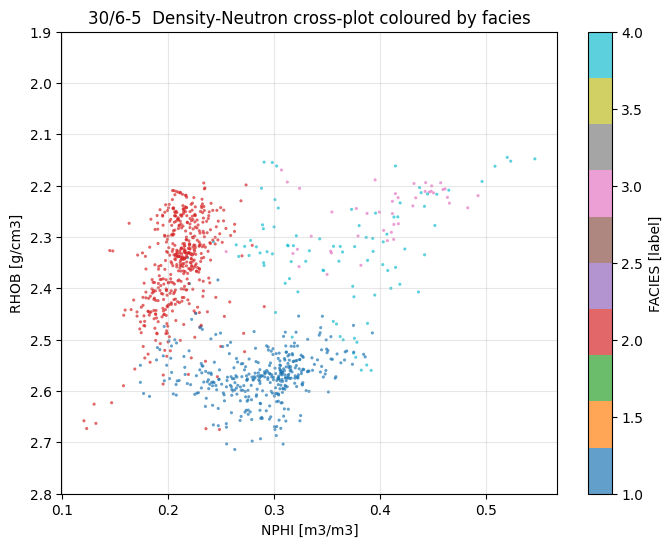

In [15]:
from petrophys.visualization import create_crossplot

# The facies labels align to the cored-interval subset (mask `m`); scatter them back
# onto the full well as a curve (NaN outside the classified interval) so the library
# crossplot can colour NPHI vs RHOB by facies directly.
facies_full = np.full(dep.shape, np.nan)
facies_full[m] = result.facies
well.add_curve('FACIES', facies_full, 'label', 'Digital-core facies (cored interval)')

xp = create_crossplot(
    well, 'NPHI', 'RHOB', color_curve='FACIES',
    depth_range=(top, bottom),
    title='30/6-5  Density-Neutron cross-plot coloured by facies',
    figsize=(8, 6),
    ylim=(2.8, 1.9),   # density increases downward
    cmap='tab10',
)
plt.show()

### 2.2 XRF geochemistry -> mineral proxies

`XRFData` holds elemental concentration logs and derives two useful products:

- `elemental_ratios()` - classic discrimination ratios (Si/Al clean-sand index,
  Ca/Al carbonate index, Mg/Ca dolomite index, ...).
- `mineral_proxies()` - normalised (0-1) quick-look mineral indicators.

> **Synthetic, illustrative.** We construct an XRF log for a made-up interval:
> a clean quartz sand at top (high Si), grading into a clay-rich interval
> (high Al, K), then a calcite-cemented streak (high Ca). Values are plausible
> weight-percents but not from a real analysis.

In [16]:
from petrophys.core import XRFData

rng = np.random.default_rng(7)
n = 120
xdepth = np.linspace(2800.0, 2812.0, n)   # 12 m illustrative interval

# Three zones: clean sand -> shale -> calcite streak
zone = np.select([xdepth < 2804, xdepth < 2809], [0, 1], default=2)
def zoned(sand, shale, carb, noise):
    base = np.select([zone == 0, zone == 1], [sand, shale], default=carb)
    return np.clip(base + rng.normal(0, noise, n), 0, None)

xrf = XRFData(
    depth=xdepth,
    elements={
        'Si': zoned(38.0, 22.0, 8.0,  1.5),
        'Al': zoned(2.0, 11.0, 1.5,   0.6),
        'Ca': zoned(0.8, 1.2, 28.0,   1.2),
        'Fe': zoned(1.0, 4.0, 0.8,    0.4),
        'K':  zoned(0.5, 3.2, 0.3,    0.2),
        'Mg': zoned(0.3, 1.1, 4.5,    0.3),
        'S':  zoned(0.1, 0.6, 0.2,    0.1),
    },
    units={e: '%' for e in ['Si', 'Al', 'Ca', 'Fe', 'K', 'Mg', 'S']},
)
print(xrf)
print('Elements:', xrf.element_names)

XRFData(samples=120, depth=2800.0-2812.0, elements=[Si, Al, Ca, Fe, K, Mg, S])
Elements: ['Si', 'Al', 'Ca', 'Fe', 'K', 'Mg', 'S']


In [17]:
ratios = xrf.elemental_ratios()
proxies = xrf.mineral_proxies()
print('Available ratios :', [k for k, v in ratios.items() if np.any(np.isfinite(v))])
print('Available proxies:', list(proxies.keys()))
print()
# Zone-average a few diagnostic ratios (ASCII names)
zone_names = {0: 'clean sand', 1: 'shale', 2: 'calcite streak'}
print('%-15s %10s %10s %10s' % ('zone', 'Si/Al', 'Ca/Al', 'Mg/Ca'))
for z in (0, 1, 2):
    mzone = zone == z
    print('%-15s %10.2f %10.2f %10.2f' % (
        zone_names[z],
        np.nanmean(ratios['Si_Al'][mzone]),
        np.nanmean(ratios['Ca_Al'][mzone]),
        np.nanmean(ratios['Mg_Ca'][mzone])))

Available ratios : ['Si_Al', 'Ca_Al', 'Fe_Al', 'K_Al', 'Mg_Ca', 'Mg_Al', 'S_Fe', 'Ca_Ca_Mg', 'Al_Al_Si']
Available proxies: ['quartz_index', 'carbonate_index', 'clay_index', 'pyrite_index', 'dolomite_index', 'siderite_index']

zone                 Si/Al      Ca/Al      Mg/Ca
clean sand           22.45       0.54       0.39
shale                 2.00       0.12       4.23
calcite streak        8.02      28.73       0.16


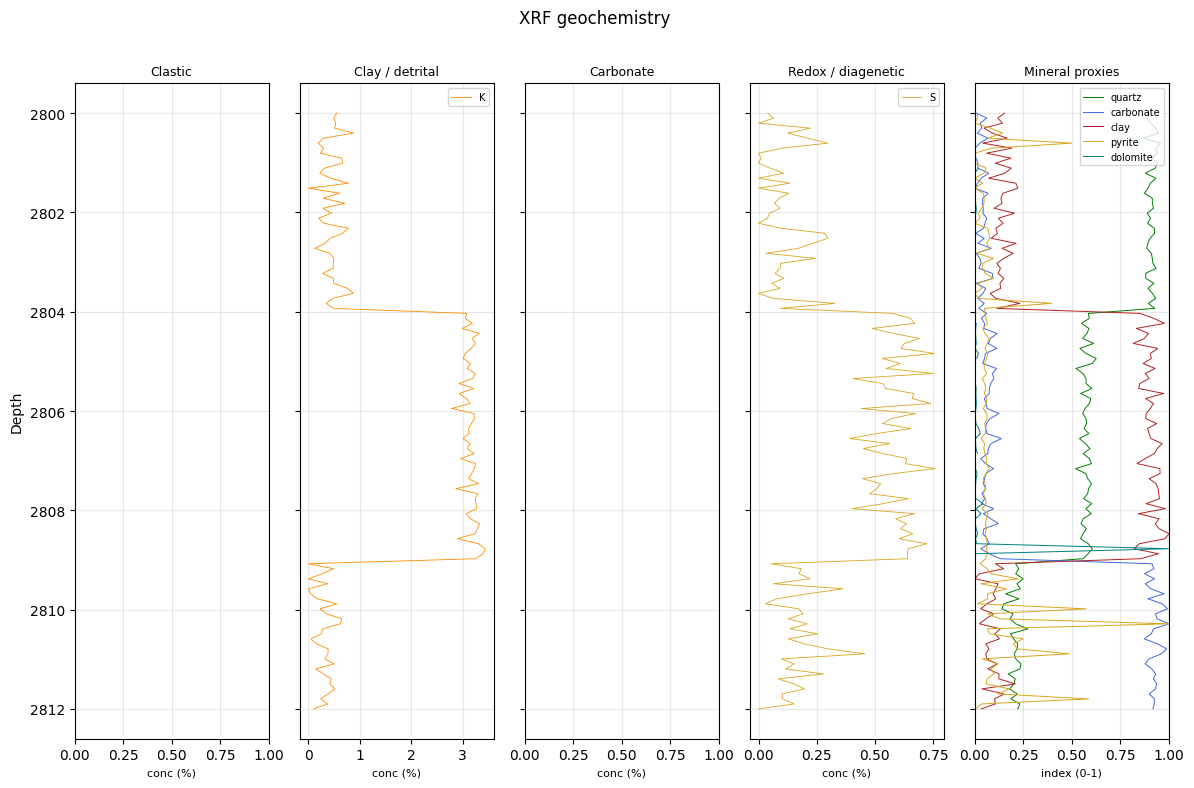

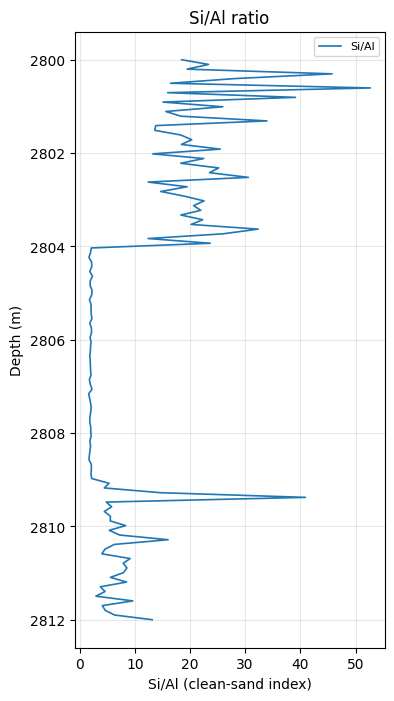

In [18]:
from petrophys.visualization import create_xrf_panel, create_line_comparison

# Element groups + mineral-proxy track straight from the XRFData object.
fig = create_xrf_panel(xrf, figsize=(12, 8))
plt.show()

# The panel does not include the Si/Al clean-sand ratio, so render it as a
# separate depth profile (Si/Al vs depth, depth increasing downward).
fig2, ax2 = create_line_comparison(
    ratios['Si_Al'], {'Si/Al': xdepth},
    invert_yaxis=True,
    xlabel='Si/Al (clean-sand index)', ylabel='Depth (m)',
    title='Si/Al ratio', figsize=(4, 8),
)
plt.show()

### 2.3 Grain size and the Wentworth scale

`GrainSizeData` stores the P13 / P50 / P87 grain diameters (um) and provides:

- `wentworth()` - the textbook size-class name per sample.
- `sorting_coefficient()` / `skewness()` - Folk & Ward distribution shape (phi units).
- `kozeny_carman_perm(porosity)` - a theoretical permeability upper bound.

The module-level helper `wentworth_class(d_um)` classifies a single diameter.

> **Synthetic, illustrative.** A fining-upward sequence: coarse sand at the base
> grading to silt at the top.

In [19]:
from petrophys.core import GrainSizeData, wentworth_class

# quick sanity check on the classifier
for d in (500, 300, 150, 40):
    print('  %4d um -> %s' % (d, wentworth_class(d)))

   500 um -> Coarse Sand
   300 um -> Medium Sand
   150 um -> Fine Sand
    40 um -> Very Coarse Silt


In [20]:
n = 80
gdepth = np.linspace(2800.0, 2808.0, n)
# fining-upward: d50 decreases toward the top (shallow)
d50 = np.linspace(60, 420, n)[::-1] + rng.normal(0, 8, n)
d50 = np.clip(d50, 5, None)
gs = GrainSizeData(depth=gdepth, d50=d50,
                   d13=np.clip(d50 * 0.55, 2, None),
                   d87=np.clip(d50 * 1.8, 5, None))
print(gs)

classes = gs.wentworth()
uniq, counts = np.unique(classes, return_counts=True)
print('\nWentworth class counts:')
for c, k in zip(uniq, counts):
    print('  %-18s %d' % (c, k))

GrainSizeData(samples=80, depth=2800.0-2808.0, d50_range=42.9-412.1 µm, data=[d50, d13, d87])

Wentworth class counts:
  Fine Sand          27
  Medium Sand        39
  Very Coarse Silt   2
  Very Fine Sand     12


Kozeny-Carman perm (phi=0.22): 182 - 16737 mD (theoretical upper bound)
Sorting (phi units)          : -0.86 - -0.86


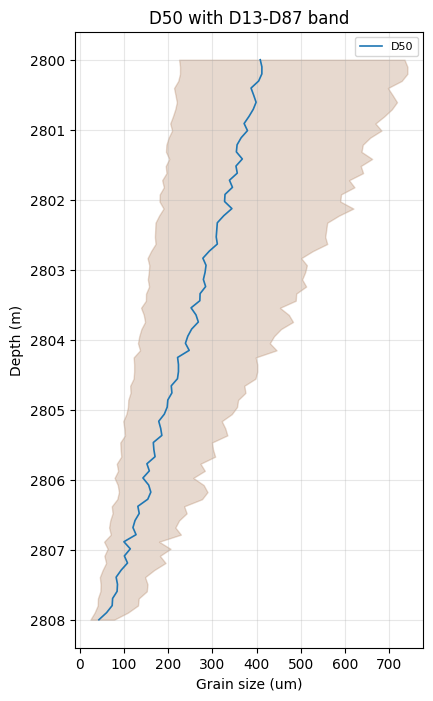

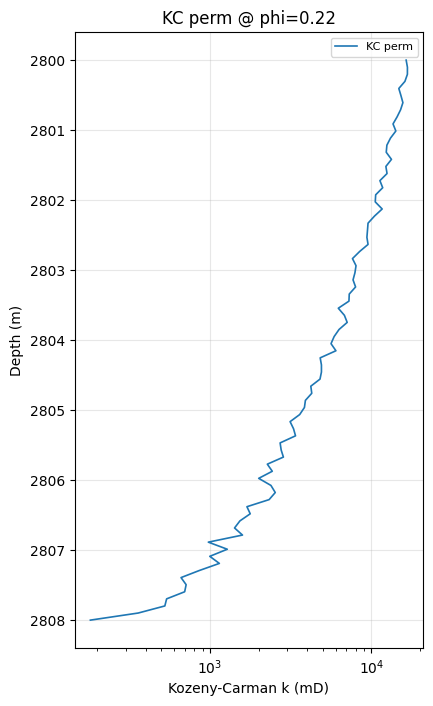

In [21]:
# Kozeny-Carman permeability at an assumed 22 percent porosity, and sorting.
kc = gs.kozeny_carman_perm(porosity=0.22)
sorting = gs.sorting_coefficient()
print('Kozeny-Carman perm (phi=0.22): %.0f - %.0f mD (theoretical upper bound)'
      % (np.nanmin(kc), np.nanmax(kc)))
print('Sorting (phi units)          : %.2f - %.2f' % (np.nanmin(sorting), np.nanmax(sorting)))

from petrophys.visualization import create_line_comparison

# D50 grain-size depth profile (line from a library call); the D13-D87 band is
# minor styling layered on the returned axis.
fig1, ax1 = create_line_comparison(
    gs.d50, {'D50': gdepth},
    invert_yaxis=True,
    xlabel='Grain size (um)', ylabel='Depth (m)',
    title='D50 with D13-D87 band', figsize=(4.5, 8),
)
ax1.fill_betweenx(gdepth, gs.d13, gs.d87, color='saddlebrown', alpha=0.2)
plt.show()

# Kozeny-Carman permeability depth profile (log x-axis).
fig2, ax2 = create_line_comparison(
    kc, {'KC perm': gdepth},
    invert_yaxis=True, logx=True,
    xlabel='Kozeny-Carman k (mD)', ylabel='Depth (m)',
    title='KC perm @ phi=0.22', figsize=(4.5, 8),
)
plt.show()

### 2.4 Core mechanical properties

`CoreMechanical` ingests continuous UCS (strength) and ultrasonic Vp / Vs, and
derives the **dynamic elastic moduli** from

$$\nu = \frac{V_P^2 - 2V_S^2}{2(V_P^2 - V_S^2)},\quad
  G = \rho V_S^2,\quad E = 2G(1+\nu),\quad
  K = \rho\left(V_P^2 - \tfrac{4}{3}V_S^2\right)$$

These feed geomechanics (wellbore stability, hydraulic-fracture design).

> **Synthetic, illustrative.** A stiff, strong cemented sand grading into a
> weaker, slower shale.

In [22]:
from petrophys.core import CoreMechanical

n = 100
mdepth = np.linspace(2800.0, 2810.0, n)
trend = np.linspace(0, 1, n)          # 0 = stiff sand, 1 = weak shale
vp = 4200 - 900 * trend + rng.normal(0, 40, n)   # m/s
vs = 2500 - 650 * trend + rng.normal(0, 30, n)   # m/s
ucs = 80 - 55 * trend + rng.normal(0, 3, n)      # MPa
mech = CoreMechanical(depth=mdepth, ucs=ucs, vp=vp, vs=vs)
print(mech)

moduli = mech.dynamic_moduli(density_gcm3=2.55)
vpvs = mech.vp_vs_ratio()
print('\nDynamic moduli (density 2.55 g/cm3):')
print('  Young E : %.1f - %.1f GPa' % (np.nanmin(moduli['young_modulus']), np.nanmax(moduli['young_modulus'])))
print("  Poisson : %.3f - %.3f" % (np.nanmin(moduli['poisson_ratio']), np.nanmax(moduli['poisson_ratio'])))
print('  Shear G : %.1f - %.1f GPa' % (np.nanmin(moduli['shear_modulus']), np.nanmax(moduli['shear_modulus'])))
print('  Vp/Vs   : %.2f - %.2f' % (np.nanmin(vpvs), np.nanmax(vpvs)))

CoreMechanical(samples=100, depth=2800.0-2810.0, data=[ucs, vp, vs])

Dynamic moduli (density 2.55 g/cm3):
  Young E : 22.2 - 39.5 GPa
  Poisson : 0.205 - 0.283
  Shear G : 8.7 - 16.0 GPa
  Vp/Vs   : 1.64 - 1.82


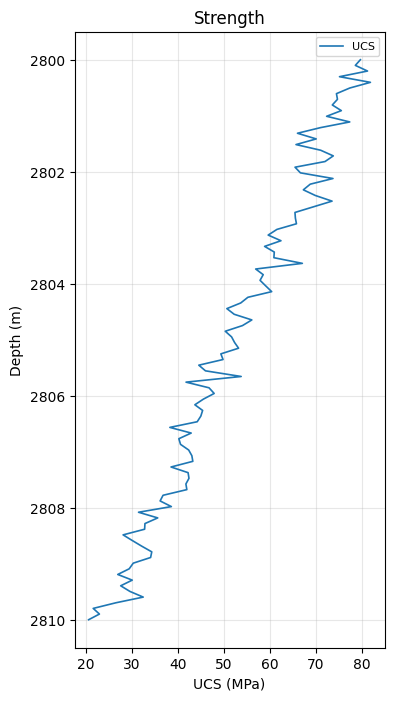

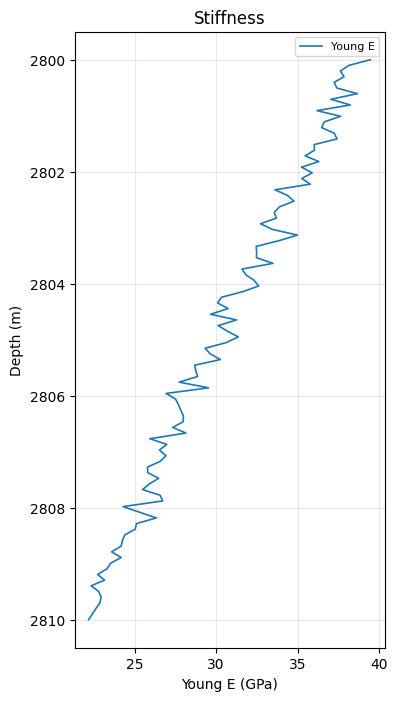

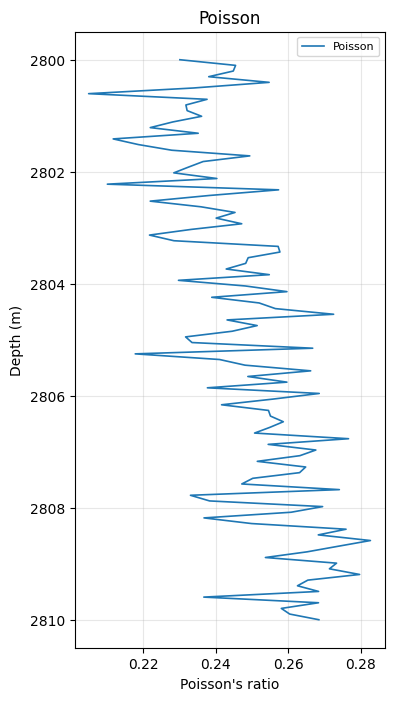

In [23]:
from petrophys.visualization import create_line_comparison

# The mechanical arrays live on their own `mdepth` grid (not the well's depth), so
# render each as a depth profile with the library line-comparison helper.
fig1, ax1 = create_line_comparison(
    mech.ucs, {'UCS': mdepth}, invert_yaxis=True,
    xlabel='UCS (MPa)', ylabel='Depth (m)', title='Strength', figsize=(4, 8),
)
plt.show()

fig2, ax2 = create_line_comparison(
    moduli['young_modulus'], {'Young E': mdepth}, invert_yaxis=True,
    xlabel='Young E (GPa)', ylabel='Depth (m)', title='Stiffness', figsize=(4, 8),
)
plt.show()

fig3, ax3 = create_line_comparison(
    moduli['poisson_ratio'], {'Poisson': mdepth}, invert_yaxis=True,
    xlabel="Poisson's ratio", ylabel='Depth (m)', title='Poisson', figsize=(4, 8),
)
plt.show()

## Pitfalls and parameter choices

- **Calibrate against an *independent* log.** Comparing a curve against itself
  gives a meaningless $R^2 = 1$. We built density porosity from RHOB specifically
  so the comparison against core `PHIC` is real.
- **Depth-matching.** Core depth and log depth are rarely on the same datum; a
  small shift can destroy an otherwise good correlation. `calibrate_porosity`
  interpolates the log to the core depths - always sanity-check the tie.
- **Poro-perm is log-linear.** Never fit permeability in linear space; a few
  high-perm plugs will dominate the least-squares fit. `fit_poro_perm_transform`
  works in $\log_{10}$ for exactly this reason.
- **Kozeny-Carman is an upper bound.** It assumes clean, uncemented, well-sorted
  grains. Real permeability is lower once you add clay and cement.
- **K-means needs scaling and sensible K.** `DigitalCoreFacies` standardises
  features for you, but *you* choose `n_facies` and the weights. Too many facies
  over-fits noise; too few merges distinct rock types.
- **Synthetic data is for teaching only.** The XRF, grain-size, and mechanical
  arrays here are illustrative constructions - never quote them as measurements.

## Recap

- `core_data_from_well` pulled 200+ real plugs off 30/6-5 into a `CoreData`.
- Density porosity calibrated against core with a modest bias and $R^2 \approx 0.65$,
  exposing the assumed-matrix-density error.
- A $\log_{10}(k)=A\phi+B$ transform propagated a handful of core-perm plugs to
  a continuous predicted-permeability curve.
- `DigitalCoreFacies` clustered real logs into named facies with a per-facies
  statistics fingerprint and a cross-plot.
- `XRFData`, `GrainSizeData`, and `CoreMechanical` turned (illustrative) scanner
  logs into mineral proxies, Wentworth classes with Kozeny-Carman perm, and
  dynamic elastic moduli.

## Try it yourself

> **Exercise 1.** Re-run the porosity calibration using a *neutron* porosity
> (`well.get('NPHI')`) instead of density porosity. Which log ties the core
> better, and what does the bias tell you about gas or clay effects?
>
> **Exercise 2.** Change `n_facies` in `DigitalCoreFacies` to 6 and add `PEF` to
> the weights. Does the inertia drop meaningfully, or are you just splitting
> noise? Inspect the new per-facies statistics table.
>
> **Exercise 3.** Feed the fitted `transform` a corrected porosity
> (via `corr.predict`) instead of raw `PHID`. How much does the predicted
> permeability profile shift?

## What's next

Continue with **13 - ML Curve Imputation**, where a pretrained gradient-boosted
model fills gaps in a missing log curve - the machine-learning counterpart to the
physics-based calibration you just did.